# AdaBoost: derivación de los pasos del algoritmo

Las notas presentan AdaBoost (Algoritmo 5.1) y dejan sin demostrar varios pasos: que minimizar la pérdida exponencial
respecto de $\boldsymbol\theta$ equivale a minimizar el error ponderado $P_i$ (ecuación 5.6), la fórmula del peso
$a_i$ y la regla de actualización de los pesos. Los demuestro aquí y agrego la cota del error de entrenamiento, que
muestra por qué AdaBoost lo lleva a cero exponencialmente rápido (es el ejercicio 5 de esa misma sección).

**Notación** (la de las notas). $N$ observaciones $(y_n,\boldsymbol x_n)$ con $y_n\in\{-1,1\}$, clasificadores base
$\phi(\boldsymbol x;\boldsymbol\theta)\in\{-1,1\}$, $F_i=F_{i-1}+a_i\phi(\cdot;\boldsymbol\theta_i)$ con $F_0=0$, y pesos
$\omega_n^{(i)}\propto\exp(-y_nF_{i-1}(\boldsymbol x_n))$ normalizados para que $\sum_n\omega_n^{(i)}=1$.

**Un hecho que se usa en todo el capítulo.** Como $y_n$ y $\phi(\boldsymbol x_n;\boldsymbol\theta)$ valen $\pm1$, su producto
vale $+1$ si el clasificador acierta y $-1$ si se equivoca. Por eso, para cualquier $a$,

$$
\exp\big(-y_na\,\phi(\boldsymbol x_n;\boldsymbol\theta)\big)=\begin{cases}e^{-a}&\text{si acierta},\\ e^{a}&\text{si se equivoca}.\end{cases}
$$ (eq-dos-valores)

## Los pesos $\omega_n^{(i)}$ salen de la pérdida exponencial

````{prf:proposition}
:label: prop-pesos
$\displaystyle\sum_{n=1}^N\exp\big(-y_n(F_{i-1}(\boldsymbol x_n)+a\phi(\boldsymbol x_n;\boldsymbol\theta))\big)=C_i\sum_{n=1}^N\omega_n^{(i)}\exp\big(-y_na\phi(\boldsymbol x_n;\boldsymbol\theta)\big)$,
con $C_i>0$ una constante que no depende de $a$ ni de $\boldsymbol\theta$.
````

```{prf:proof}
Por la propiedad $e^{u+v}=e^ue^v$, cada sumando es $\exp(-y_nF_{i-1}(\boldsymbol x_n))\exp(-y_na\phi(\boldsymbol x_n;\boldsymbol\theta))$. El primer
factor es $C_i\,\omega_n^{(i)}$, donde $C_i=\sum_m\exp(-y_mF_{i-1}(\boldsymbol x_m))$ es la constante de normalización, y solo
depende de pasos anteriores.
```

Multiplicar el costo por $C_i>0$ no cambia dónde está el mínimo, así que el problema (5.4) equivale a minimizar
$\sum_n\omega_n^{(i)}\exp(-y_na\phi(\boldsymbol x_n;\boldsymbol\theta))$, que es (5.5). (En la primera línea de (5.5) las notas
escriben $\operatorname{argmin}_{a,\boldsymbol\theta}$; como $a$ está fijo en ese paso, es $\operatorname{argmin}_{\boldsymbol\theta}$.)

## Elegir $\boldsymbol\theta_i$ es minimizar el error ponderado

````{prf:proposition} Ecuación 5.6
:label: prop-56
Para $a>0$ fijo, $\displaystyle\operatorname*{argmin}_{\boldsymbol\theta}\sum_n\omega_n^{(i)}e^{-y_na\phi(\boldsymbol x_n;\boldsymbol\theta)}=\operatorname*{argmin}_{\boldsymbol\theta}P_i(\boldsymbol\theta)$,
donde $P_i(\boldsymbol\theta)=\sum_n\omega_n^{(i)}\,\chi_{(-\infty,0]}\big(y_n\phi(\boldsymbol x_n;\boldsymbol\theta)\big)$ es la suma de los pesos de los
puntos mal clasificados.
````

```{prf:proof}
Separo la suma en aciertos y errores con {eq}`eq-dos-valores`. Los pesos suman $1$, así que los aciertos pesan
$1-P_i(\boldsymbol\theta)$:

$$
\sum_n\omega_n^{(i)}e^{-y_na\phi(\boldsymbol x_n;\boldsymbol\theta)}=e^{-a}\big(1-P_i(\boldsymbol\theta)\big)+e^{a}P_i(\boldsymbol\theta)
=e^{-a}+\big(e^{a}-e^{-a}\big)P_i(\boldsymbol\theta).
$$

Con $a>0$ fijo, $e^{-a}$ es una constante y $e^{a}-e^{-a}>0$. El costo es una función afín **creciente** de
$P_i(\boldsymbol\theta)$, así que se minimiza exactamente donde se minimiza $P_i(\boldsymbol\theta)$.
```

Esta es la razón por la que el clasificador base se entrena para minimizar su error **ponderado**: los puntos
difíciles, con más peso, cuentan más.

## El peso del clasificador: $a_i=\tfrac12\ln\frac{1-P_i}{P_i}$

````{prf:proposition}
:label: prop-a
Sea $P_i=P_i(\boldsymbol\theta_i)\in(0,1)$. La función $J(a)=e^{-a}(1-P_i)+e^{a}P_i$ tiene un único mínimo global en

$$
a_i=\frac12\ln\frac{1-P_i}{P_i},\qquad\text{y en ese punto}\qquad J(a_i)=2\sqrt{P_i(1-P_i)} .
$$ (eq-ai)
````

```{prf:proof}
Por la demostración de la {prf:ref}`prop-56`, $J(a)$ es el costo (5.5) evaluado en $\boldsymbol\theta_i$. Derivando,

$$
J'(a)=-e^{-a}(1-P_i)+e^{a}P_i,\qquad J''(a)=e^{-a}(1-P_i)+e^{a}P_i>0 .
$$

Como $J''>0$, $J$ es estrictamente convexa y su único punto crítico es el mínimo global. Igualando $J'(a)=0$ y
multiplicando por $e^{a}>0$: $e^{2a}P_i=1-P_i$, es decir, $e^{2a}=\frac{1-P_i}{P_i}$ y $a=\frac12\ln\frac{1-P_i}{P_i}$.

Para el valor mínimo, $e^{a_i}=\sqrt{\frac{1-P_i}{P_i}}$ y $e^{-a_i}=\sqrt{\frac{P_i}{1-P_i}}$, así que
$J(a_i)=\sqrt{\frac{P_i}{1-P_i}}(1-P_i)+\sqrt{\frac{1-P_i}{P_i}}P_i=\sqrt{P_i(1-P_i)}+\sqrt{P_i(1-P_i)}=2\sqrt{P_i(1-P_i)}$.
```

**Signo de $a_i$.** $a_i>0\iff\frac{1-P_i}{P_i}>1\iff P_i<\frac12$: el clasificador base debe ser mejor que lanzar una
moneda **con los pesos actuales**, lo que justifica el supuesto $a>0$ de la {prf:ref}`prop-56`. Si $P_i=\frac12$,
$a_i=0$ y el clasificador no aporta; un clasificador con $P_i>\frac12$ recibiría peso negativo, que equivale a
invertir sus predicciones. Los casos extremos $P_i=0$ (clasificador perfecto) y $P_i=1$ dan $a_i=\pm\infty$; en la
práctica se detiene el algoritmo o se acota $P_i$.

```{warning} Paréntesis del paso 3 del Algoritmo 5.1
El paso 3 está escrito como $a_i=1/2[\ln(1-P_i)/P_i]$, que se puede leer como $\frac{\ln(1-P_i)}{2P_i}$. La expresión
correcta, la que se acaba de demostrar, es $a_i=\frac12\ln\!\big(\frac{1-P_i}{P_i}\big)$: el logaritmo es del cociente.
```

## La regla de actualización de los pesos

````{prf:proposition}
:label: prop-update
$\displaystyle\omega_n^{(i+1)}=\frac{\omega_n^{(i)}\exp\big(-y_na_i\phi(\boldsymbol x_n;\boldsymbol\theta_i)\big)}{Z_i}$, con
$Z_i=\sum_n\omega_n^{(i)}\exp\big(-y_na_i\phi(\boldsymbol x_n;\boldsymbol\theta_i)\big)=2\sqrt{P_i(1-P_i)}$.
````

```{prf:proof}
Por definición, $\omega_n^{(i+1)}\propto\exp(-y_nF_i(\boldsymbol x_n))=\exp(-y_nF_{i-1}(\boldsymbol x_n))\exp(-y_na_i\phi(\boldsymbol x_n;\boldsymbol\theta_i))
\propto\omega_n^{(i)}\exp(-y_na_i\phi(\boldsymbol x_n;\boldsymbol\theta_i))$. Para que los nuevos pesos sumen $1$ hay que dividir por la
suma, que es $Z_i$. Esa suma es $J(a_i)$, que por la {prf:ref}`prop-a` vale $2\sqrt{P_i(1-P_i)}$.
```

Esto es lo que hacen los pasos 4 a 8 del algoritmo: el bucle del paso 5 multiplica y acumula $Z_i$, y el del paso 7
normaliza. Por {eq}`eq-dos-valores`, un punto mal clasificado multiplica su peso por $e^{a_i}>1$ y uno bien clasificado
por $e^{-a_i}<1$, que es la afirmación de las notas sobre los puntos difíciles.

````{prf:corollary} El clasificador recién agregado queda "en empate" con los pesos nuevos
:label: cor-medio
Con los pesos $\omega^{(i+1)}$, el error ponderado de $\phi(\cdot;\boldsymbol\theta_i)$ es exactamente $\frac12$.
````

```{prf:proof}
Los mal clasificados pesaban $P_i$ en total y se multiplican por $e^{a_i}=\sqrt{(1-P_i)/P_i}$:

$$
\sum_{\text{errores}}\omega_n^{(i+1)}=\frac{P_i\sqrt{(1-P_i)/P_i}}{2\sqrt{P_i(1-P_i)}}=\frac{\sqrt{P_i(1-P_i)}}{2\sqrt{P_i(1-P_i)}}=\frac12 .
$$
```

Por eso el siguiente clasificador base no puede ser el mismo: con los pesos nuevos ese clasificador no es mejor que
el azar, así que la siguiente iteración busca uno que acierte donde el anterior falló.

## El error de entrenamiento cae exponencialmente

````{prf:proposition}
:label: prop-cota
Con pesos iniciales $\omega_n^{(1)}=1/N$, el error de entrenamiento de $f=\operatorname{sgn}(F_K)$ cumple

$$
\begin{aligned}
\frac1N\sum_{n=1}^N\mathbb 1\{f(\boldsymbol x_n)\neq y_n\}&\le\prod_{i=1}^K Z_i=\prod_{i=1}^K2\sqrt{P_i(1-P_i)}\\
&\le\exp\Big(-2\sum_{i=1}^K\gamma_i^2\Big),\qquad\gamma_i:=\tfrac12-P_i .
\end{aligned}
$$
````

```{prf:proof}
*Paso 1: la pérdida 0-1 está debajo de la exponencial.* Si $f(\boldsymbol x_n)\neq y_n$, entonces $y_nF_K(\boldsymbol x_n)\le0$
y $\exp(-y_nF_K(\boldsymbol x_n))\ge1$; si acierta, la indicadora vale $0$ y la exponencial es positiva. Por tanto
$\mathbb 1\{f(\boldsymbol x_n)\neq y_n\}\le\exp(-y_nF_K(\boldsymbol x_n))$.

*Paso 2: desenrollar la recursión de los pesos.* Aplicando la {prf:ref}`prop-update` $K$ veces desde $\omega_n^{(1)}=1/N$,

$$
\omega_n^{(K+1)}=\frac{\frac1N\exp\big(-y_n\sum_{i=1}^Ka_i\phi(\boldsymbol x_n;\boldsymbol\theta_i)\big)}{\prod_{i=1}^KZ_i}=\frac{\frac1N\exp(-y_nF_K(\boldsymbol x_n))}{\prod_{i=1}^KZ_i}.
$$

Como los $\omega_n^{(K+1)}$ suman $1$, sumando en $n$: $\frac1N\sum_n\exp(-y_nF_K(\boldsymbol x_n))=\prod_iZ_i$. Junto con el
paso 1 se obtiene la primera desigualdad.

*Paso 3: cota de cada factor.* Con $P_i=\frac12-\gamma_i$, $4P_i(1-P_i)=4(\frac12-\gamma_i)(\frac12+\gamma_i)=1-4\gamma_i^2$,
así que $Z_i=\sqrt{1-4\gamma_i^2}$. Usando $1+u\le e^{u}$ con $u=-4\gamma_i^2$: $Z_i\le\sqrt{e^{-4\gamma_i^2}}=e^{-2\gamma_i^2}$.
Multiplicando los $K$ factores se obtiene la última desigualdad.
```

**Consecuencia.** Si cada clasificador base es al menos un poco mejor que el azar con los pesos que recibe, es decir,
$P_i\le\frac12-\gamma$ para algún $\gamma>0$, el error de entrenamiento es a lo sumo $e^{-2K\gamma^2}$: cae
**exponencialmente** con el número de iteraciones. Además, como solo puede tomar los valores $0,\frac1N,\frac2N,\dots$,
se vuelve exactamente $0$ en cuanto $e^{-2K\gamma^2}<\frac1N$, es decir, para $K>\frac{\ln N}{2\gamma^2}$.

## Verificación numérica

Implemento el Algoritmo 5.1 con tocones de decisión (árboles de profundidad 1, entrenados con pesos) sobre datos
simulados, y compruebo en cada iteración la fórmula de $a_i$, el valor de $Z_i$, el {prf:ref}`cor-medio` y la cota.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
from sklearn.datasets import make_classification
from sklearn.tree import DecisionTreeClassifier

X, y01 = make_classification(n_samples=400, n_features=6, n_informative=4, random_state=3)
y = 2 * y01 - 1                                   # etiquetas en {-1, 1}
N, K = len(y), 60
w = np.full(N, 1 / N)                             # paso de inicialización
F = np.zeros(N)
filas = []
for i in range(1, K + 1):
    tocon = DecisionTreeClassifier(max_depth=1, random_state=i).fit(X, y, sample_weight=w)
    phi = tocon.predict(X)
    P = w[phi != y].sum()                                         # error ponderado P_i
    a = 0.5 * np.log((1 - P) / P)                                 # paso 3, fórmula demostrada
    a_num = minimize_scalar(lambda t: np.exp(-t) * (1 - P) + np.exp(t) * P).x   # mínimo numérico de J(a)
    nuevo = w * np.exp(-y * a * phi)
    Z = nuevo.sum()
    w = nuevo / Z                                                 # pasos 5 a 8
    F += a * phi
    filas.append({"i": i, "P_i": P, "a_i (fórmula)": a, "a_i (numérico)": a_num,
                  "Z_i": Z, "2 sqrt(P(1-P))": 2 * np.sqrt(P * (1 - P)),
                  "error ponderado de phi_i con pesos nuevos": w[phi != y].sum(),
                  "error de entrenamiento": np.mean(np.sign(F) != y)})
tabla = pd.DataFrame(filas)
tabla["cota prod Z_i"] = tabla["Z_i"].cumprod()
tabla["cota exp(-2 sum gamma^2)"] = np.exp(-2 * np.cumsum((0.5 - tabla["P_i"]) ** 2))
print("max |a fórmula - a numérico|:", np.abs(tabla["a_i (fórmula)"] - tabla["a_i (numérico)"]).max().round(8))
print("max |Z_i - 2 sqrt(P(1-P))|:", np.abs(tabla["Z_i"] - tabla["2 sqrt(P(1-P))"]).max().round(12))
print("error ponderado del tocón anterior con los pesos nuevos: entre",
      tabla.iloc[:, 6].min().round(12), "y", tabla.iloc[:, 6].max().round(12))
print("¿la cota se cumple en todas las iteraciones?",
      bool((tabla["error de entrenamiento"] <= tabla["cota prod Z_i"] + 1e-12).all()
           and (tabla["cota prod Z_i"] <= tabla["cota exp(-2 sum gamma^2)"] + 1e-12).all()))
tabla.iloc[[0, 1, 2, 9, 29, 59]].round(4)

max |a fórmula - a numérico|: 2e-08
max |Z_i - 2 sqrt(P(1-P))|: 0.0
error ponderado del tocón anterior con los pesos nuevos: entre 0.5 y 0.5
¿la cota se cumple en todas las iteraciones? True


,i,P_i,a_i (fórmula),a_i (numérico),Z_i,2 sqrt(P(1-P)),error ponderado de phi_i con pesos nuevos,error de entrenamiento,cota prod Z_i,cota exp(-2 sum gamma^2)
0,1,0.3025,0.4177,0.4177,0.9187,0.9187,0.5,0.3025,0.9187,0.9250
1,2,0.2586,0.5267,0.5267,0.8757,0.8757,0.5,0.3150,0.8045,0.8232
2,3,0.2926,0.4414,0.4414,0.9099,0.9099,0.5,0.1675,0.7320,0.7553
9,10,0.3967,0.2096,0.2096,0.9784,0.9784,0.5,0.1550,0.5868,0.6112
29,30,0.4657,0.0686,0.0686,0.9976,0.9976,0.5,0.1275,0.5260,0.5484
59,60,0.4874,0.0252,0.0252,0.9997,0.9997,0.5,0.1025,0.4749,0.4955


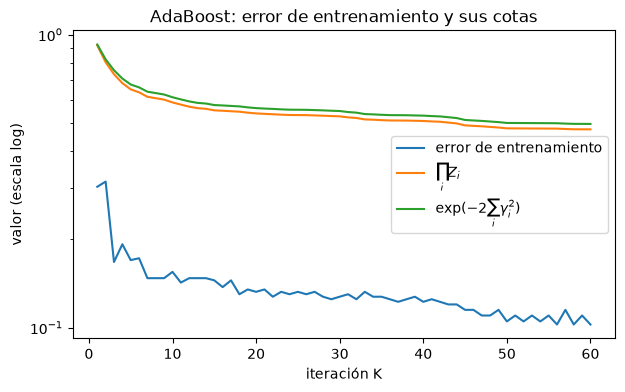

In [2]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(tabla["i"], tabla["error de entrenamiento"], label="error de entrenamiento")
ax.plot(tabla["i"], tabla["cota prod Z_i"], label=r"$\prod_i Z_i$")
ax.plot(tabla["i"], tabla["cota exp(-2 sum gamma^2)"], label=r"$\exp(-2\sum_i\gamma_i^2)$")
ax.set(yscale="log", xlabel="iteración K", ylabel="valor (escala log)", title="AdaBoost: error de entrenamiento y sus cotas")
ax.legend()
plt.show()

La fórmula cerrada de $a_i$ coincide con la minimización numérica de $J(a)$; $Z_i=2\sqrt{P_i(1-P_i)}$ en todas las
iteraciones; el tocón recién agregado tiene error ponderado exactamente $\frac12$ con los pesos nuevos; y el error de
entrenamiento queda siempre por debajo de $\prod_iZ_i$, que a su vez queda por debajo de $\exp(-2\sum_i\gamma_i^2)$.

La tabla también muestra el **supuesto** de la caída exponencial. En las primeras iteraciones $P_i\approx0.26$–$0.30$
($\gamma_i\approx0.2$) y la cota baja rápido; después los tocones tienen cada vez más dificultad con los pesos que
reciben ($P_{60}\approx0.49$, $\gamma_{60}\approx0.01$), cada $Z_i$ queda cerca de $1$ y la cota baja despacio. Esto
no contradice la {prf:ref}`prop-cota`: la caída es exponencial **mientras** $\gamma_i\ge\gamma>0$. Un tocón (un solo
corte en una variable) es un clasificador muy débil para estos datos. Repitiendo las mismas $60$ iteraciones con
árboles base más profundos, $\gamma_i$ se mantiene más lejos de cero: con profundidad $2$ el error de entrenamiento
termina en $2\,\%$ y con profundidad $3$ llega a $0$.

**Referencias.** Freund, Y. y Schapire, R. E. (1997). A decision-theoretic generalization of on-line learning and an
application to boosting. *Journal of Computer and System Sciences*, 55(1), 119–139. · Theodoridis, S. (2020).
*Machine Learning: A Bayesian and Optimization Perspective* (2.ª ed.), cap. 7. Academic Press.